# EDA для e-commerce за октябрь

# Первичный осмотр

Будем использовать библиотеку `duckdb` для работы с большим количеством данных, а `pandas` уже для обработки мелких групп

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import duckdb 

In [ ]:
path = 'D:/kaggle_data/2019-Oct.csv'

con = duckdb.connect('ecommerce.duckdb')

con.execute(f"""
    CREATE TABLE events AS
    SELECT * FROM read_csv_auto('{path}')            
""")

con.close()

In [3]:
con = duckdb.connect('ecommerce.duckdb')

con.sql("""
    SELECT *
    FROM events
    LIMIT 5
    """
).show()


# df = pd.read_csv(path, nrows=1000000)
# df.head(5)

┌─────────────────────┬────────────┬────────────┬─────────────────────┬─────────────────────────────────────┬──────────┬─────────┬───────────┬──────────────────────────────────────┐
│     event_time      │ event_type │ product_id │     category_id     │            category_code            │  brand   │  price  │  user_id  │             user_session             │
│      timestamp      │  varchar   │   int64    │        int64        │               varchar               │ varchar  │ double  │   int64   │               varchar                │
├─────────────────────┼────────────┼────────────┼─────────────────────┼─────────────────────────────────────┼──────────┼─────────┼───────────┼──────────────────────────────────────┤
│ 2019-10-01 00:00:00 │ view       │   44600062 │ 2103807459595387724 │ NULL                                │ shiseido │   35.79 │ 541312140 │ 72d76fde-8bb3-4e00-8c23-a032dfed738c │
│ 2019-10-01 00:00:00 │ view       │    3900821 │ 2053013552326770905 │ appliances.environ

## Общие сведения

In [4]:
con.sql('SUMMARIZE events').df()

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,event_time,TIMESTAMP,2019-10-01 00:00:00,2019-10-31 23:59:59,2675444,2019-10-16 13:03:06.605022,NaN,2019-10-09 08:06:10.638617,2019-10-16 11:39:23.716018,2019-10-23 20:13:31.67273,42448764,0.00
1,event_type,VARCHAR,cart,view,3,NaN,NaN,NaN,NaN,NaN,42448764,0.00
2,product_id,BIGINT,1000978,60500010,177851,10549932.375842676,11881906.970608188,1005157,4969528,16119969,42448764,0.00
3,category_id,BIGINT,2053013552226107603,2175419595093967522,872,2.0574042379407946e+18,1.843926466140267e+16,2053013555445508352,2053013555632068096,2053013563354345472,42448764,0.00
4,category_code,VARCHAR,accessories.bag,stationery.cartrige,121,NaN,NaN,NaN,NaN,NaN,42448764,31.84
5,brand,VARCHAR,a-case,zyxel,3516,NaN,NaN,NaN,NaN,NaN,42448764,14.40
6,price,DOUBLE,0.0,2574.07,78322,290.32366068491314,358.26915533940297,66.03641844042045,163.29359703799244,357.4353441068819,42448764,0.00
7,user_id,BIGINT,33869381,566280860,3455844,533537147.50816846,18523738.17465305,515911550,529663209,551512275,42448764,0.00
8,user_session,VARCHAR,00000042-3e3f-42f9-810d-f3d264139c50,fffffc65-7ce9-435c-8b72-1d9f7062fe77,11390309,NaN,NaN,NaN,NaN,NaN,42448764,0.00


In [5]:
df_size = con.sql("""
           SELECT COUNT(*) AS nRow
           FROM events
           """).df()
nCol = con.sql("""
               SELECT *
               FROM events
               LIMIT 1
               """).df().shape[1]
df_size['nCol'] = nCol
df_size

#nRow, nCol = df.shape
#print(f'There are {nCol} columns and {nRow} rows')

,nRow,nCol
0,42448764,9


### Посчитаем отдельно ключевые параметры

Посчитаем пустые значения:

In [6]:
nulls = con.sql("""
                   SELECT count(*) FILTER(WHERE event_time IS NULL) as event_time, 
                    count(*) FILTER(WHERE event_type IS NULL) as event_type, 
                    count(*) FILTER(WHERE product_id IS NULL) as product_id, 
                    count(*) FILTER(WHERE category_id IS NULL) as category_id, 
                    count(*) FILTER(WHERE category_code IS NULL) as category_code, 
                    count(*) FILTER(WHERE brand IS NULL) as brand, 
                    count(*) FILTER(WHERE price IS NULL) as price, 
                    count(*) FILTER(WHERE user_id IS NULL) as user_id, 
                    count(*) FILTER(WHERE user_session IS NULL) as user_session, 
                   
                   FROM events
""").df()
# print('Quantity of not a number elements: \n',df.isna().sum())
# print("\nMean value of not a number in our columns: \n", df.isna().mean().round(2)*100)
# 
# print("\nHow many duplicates in our data frame->", df.duplicated().sum())

In [7]:
nulls.T

,0
event_time,0
event_type,0
product_id,0
category_id,0
category_code,13515609
brand,6113008
price,0
user_id,0
user_session,2


Посмотрим какие вообще значения принимают столбцы, где хранятся категории товаров:

In [8]:
con.sql("""
                  SELECT 'event_type' AS col, COUNT(DISTINCT event_type) AS nunique, list(DISTINCT event_type)[:5] AS sample
                  FROM events
                  UNION ALL
                  SELECT 'category_code', COUNT(DISTINCT category_code), list(DISTINCT category_code)[:5]
                  FROM events
                  UNION ALL
                  SELECT 'brand', COUNT(DISTINCT brand), list(DISTINCT brand)[:5]
                  FROM events
                  """).show()

┌───────────────┬─────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│      col      │ nunique │                                                            sample                                                            │
│    varchar    │  int64  │                                                          varchar[]                                                           │
├───────────────┼─────────┼──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ event_type    │       3 │ [purchase, cart, view]                                                                                                       │
│ category_code │     126 │ [NULL, appliances.kitchen.juicer, appliances.environment.vacuum, electronics.telephone, electronics.audio.music_tools.piano] │
│ brand         │    3445 │ [jvc, lenovo, samsung, alesis, midea]     

Бренды и их наиболее часто покупаемые категории:

In [9]:
con.sql('''
        WITH cnt_cat AS(
            SELECT brand, category_code, COUNT(*) as cnt
            FROM events
            WHERE event_type='purchase' AND category_code IS NOT NULL AND brand IS NOT NULL
            GROUP BY brand, category_code
            ORDER BY brand
        ),
        ranked_cat AS(
            SELECT brand, category_code, 
            ROW_NUMBER() OVER(PARTITION BY brand
                              ORDER BY cnt DESC) as rn, cnt
            FROM cnt_cat
            ORDER BY brand
        )
        SELECT brand, category_code, cnt AS count
        FROM ranked_cat
        WHERE rn=1
        ORDER BY count DESC
        LIMIT 10
        
''').show()

┌─────────┬───────────────────────────┬────────┐
│  brand  │       category_code       │ count  │
│ varchar │          varchar          │ int64  │
├─────────┼───────────────────────────┼────────┤
│ samsung │ electronics.smartphone    │ 143123 │
│ apple   │ electronics.smartphone    │ 115345 │
│ xiaomi  │ electronics.smartphone    │  38776 │
│ huawei  │ electronics.smartphone    │  21882 │
│ oppo    │ electronics.smartphone    │  10891 │
│ acer    │ computers.notebook        │   6018 │
│ lenovo  │ computers.notebook        │   3990 │
│ artel   │ electronics.video.tv      │   3053 │
│ lg      │ appliances.kitchen.washer │   2903 │
│ indesit │ appliances.kitchen.washer │   2660 │
└─────────┴───────────────────────────┴────────┘
  10 rows                            3 columns



Количество продаж по дням:

<Axes: >

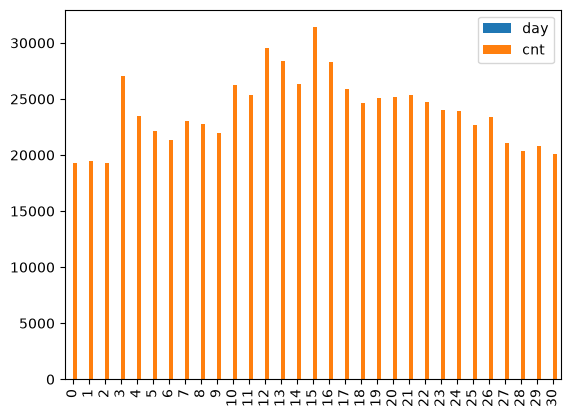

In [29]:
cnt_sale_per_day = con.sql('''
        SELECT EXTRACT(day FROM event_time) as day, COUNT(*) as cnt
        FROM events
        WHERE event_type='purchase'
        GROUP BY EXTRACT(day FROM event_time)
''').df()

cnt_sale_per_day.plot.bar()

Выручка по дням:

<Axes: >

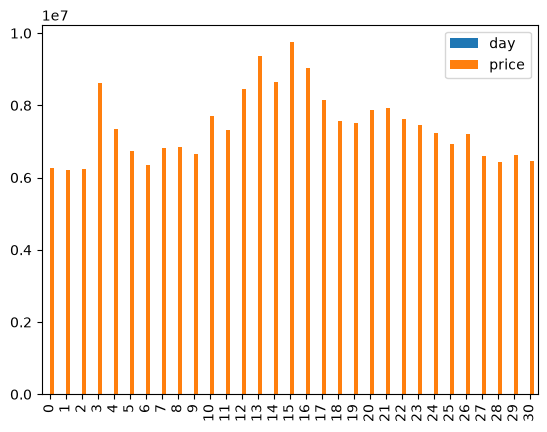

In [32]:
price_sale_per_day = con.sql('''
        SELECT EXTRACT(day FROM event_time) as day, SUM(price) as price
        FROM events
        WHERE event_type='purchase'
        GROUP BY EXTRACT(day FROM event_time)
''').df()

price_sale_per_day.plot.bar()

Посмотрим самое ранние и самое позднее время транзакций:

In [37]:
con.sql("""
        SELECT MAX(event_time) AS last_transaction, MIN(event_time) AS early_transaction
        FROM events
        """).show()

┌─────────────────────┬─────────────────────┐
│  last_transaction   │  early_transaction  │
│      timestamp      │      timestamp      │
├─────────────────────┼─────────────────────┤
│ 2019-10-31 23:59:59 │ 2019-10-01 00:00:00 │
└─────────────────────┴─────────────────────┘



Количество уникальных пользователей:

In [38]:
unique_user = con.sql('''
                        SELECT COUNT(DISTINCT user_id) AS cnt_of_user
                        FROM events
                        ''').df()
unique_user

,cnt_of_user
0,3022290


Количество уникальных сессий:

In [39]:
unique_session = con.sql('''
                        SELECT COUNT(DISTINCT user_session) AS cnt_of_session
                        FROM events
                        ''').df()
unique_session

,cnt_of_session
0,9244421


Сколько сессий среднем приходится на одного пользователя:

In [40]:
con.sql("""
        WITH user_ses_cnt AS(
                SELECT COUNT(DISTINCT user_session) as cnt
                FROM events
                GROUP BY user_id
        )
        SELECT ROUND(AVG(cnt), 2) AS avg_session_per_user
        FROM user_ses_cnt
        """).show()

┌──────────────────────┐
│ avg_session_per_user │
│        double        │
├──────────────────────┤
│                 3.06 │
└──────────────────────┘



## Статистические сведения

### Распределение этапов

Найдем отношение $\frac{\text{кол-во прошедших этап (или находятся на нём)}}{\text{все люди}}$ для каждого этапа 

  event_type       cnt    pct
0       view  40779399  96.07
1       cart    926516   2.18
2   purchase    742849   1.75


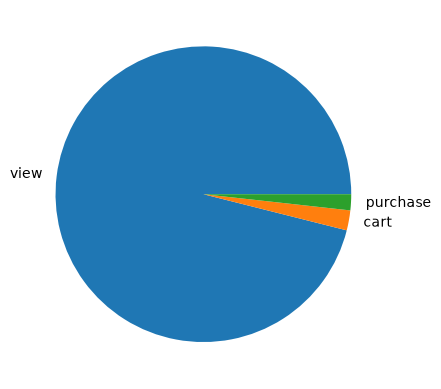

In [41]:
event_cnt = con.sql("""
        SELECT event_type, 
            COUNT(*) as cnt, 
            ROUND(COUNT(*) / SUM(COUNT(*)) OVER() * 100, 2) AS pct
        FROM events
        GROUP BY event_type
        """).df()
print(event_cnt)
plt.pie(event_cnt['cnt'], labels=event_cnt['event_type'])
plt.show()

### Сделаем строгую воронку этапов _по сессиям_

In [34]:
session_funnel = con.sql("""
        WITH views AS(
            SELECT user_session, MIN(event_time) AS t_view
            FROM events 
            WHERE event_type='view'
            GROUP BY user_session
        ),
        carts AS(
            SELECT e.user_session, MIN(e.event_time) AS t_cart
            FROM events e JOIN views v USING(user_session)
            WHERE e.event_type='cart' AND e.event_time >= v.t_view
            GROUP BY e.user_session
        ),
        purchase AS(
            SELECT e.user_session, MIN(e.event_time) AS t_purchase
            FROM events e JOIN carts c USING(user_session)
            WHERE e.event_type='purchase' AND e.event_time >= c.t_cart
            GROUP BY e.user_session
        )
        
        SELECT (SELECT COUNT(*) FROM views) as viewed,
               (SELECT COUNT(*) FROM carts) as carted,
               (SELECT COUNT(*) FROM purchase) as purchased
        """).df()

    viewed  carted  purchased
0  9242653  571061     289507
   viewed  carted  purchased
0   100.0    6.18       3.13


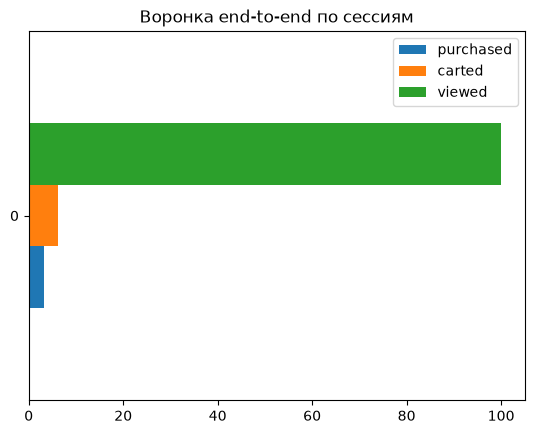

In [36]:
print(session_funnel)

pct_session_funnel = session_funnel.copy()

pct_session_funnel['viewed']=(session_funnel['viewed']/session_funnel['viewed']*100).round(2)
pct_session_funnel['carted']=(session_funnel['carted']/session_funnel['viewed']*100).round(2)
pct_session_funnel['purchased']=(session_funnel['purchased']/session_funnel['viewed']*100).round(2)

print(pct_session_funnel)
pct_session_funnel[['purchased', 'carted', 'viewed']].plot.barh(title='Воронка end-to-end по сессиям')  
plt.show()

__Конверсии__ $viewed\rightarrow cart$, $cart\rightarrow purchased$ 

In [44]:
CR_session = pd.DataFrame()

CR_session['v_to_c'] = (session_funnel['carted']/session_funnel['viewed']*100).round(2) 
CR_session['c_to_p'] = (session_funnel['purchased']/session_funnel['carted']*100).round(2) 

CR_session

,v_to_c,c_to_p
0,6.18,50.7


### Сделаем воронку, но теперь не по сессиям, а _по пользователям_

In [33]:
users_funnel = con.sql('''
    WITH viewed AS(
        SELECT user_id, MIN(event_time) as t_v
        FROM events
        WHERE event_type = 'view'
        GROUP BY user_id
    ),
    carted AS(
        SELECT e.user_id, MIN(e.event_time) as t_c
        FROM events e JOIN viewed v ON e.user_id = v.user_id AND e.event_time >= t_v
        WHERE event_type = 'cart' 
        GROUP BY e.user_id
    ),
    purchased AS(
        SELECT e.user_id, MIN(e.event_time) as t_p
        FROM events e JOIN carted c ON e.user_id = c.user_id AND e.event_time >= t_c
        WHERE event_type = 'purchase'
        GROUP BY e.user_id 
    )        
    SELECT (SELECT COUNT(*) FROM viewed) AS viewed,
           (SELECT COUNT(*) FROM carted) AS carted,
           (SELECT COUNT(*) FROM purchased) AS purchased
''').df()

    viewed  carted  purchased
0  3022130  336812     196505
   viewed  carted  purchased
0   100.0   11.14        6.5


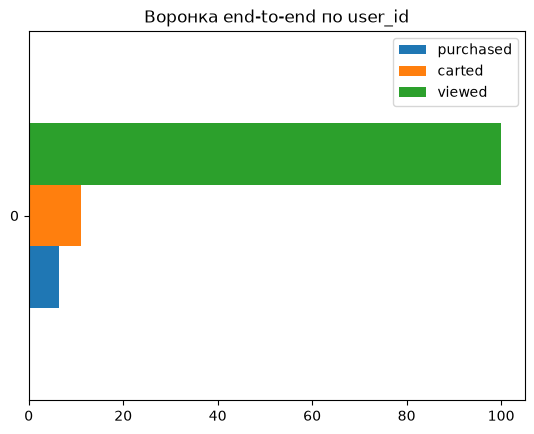

In [35]:
print(users_funnel)

pct_users_funnel = users_funnel.copy()

pct_users_funnel['viewed'] = (users_funnel['viewed']/users_funnel['viewed']*100).round(2)
pct_users_funnel['carted'] = (users_funnel['carted']/users_funnel['viewed']*100).round(2)
pct_users_funnel['purchased'] = (users_funnel['purchased']/users_funnel['viewed']*100).round(2)

print(pct_users_funnel)

pct_users_funnel[['purchased', 'carted', 'viewed']].plot.barh(title='Воронка end-to-end по user_id')
plt.show()

__Конверсии__ $viewed\rightarrow cart$, $cart\rightarrow purchased$ 

In [42]:
CR_users = pd.DataFrame()

CR_users['v_to_c'] = (users_funnel['carted']/users_funnel['viewed']*100).round(2) 
CR_users['c_to_p'] = (users_funnel['purchased']/users_funnel['carted']*100).round(2) 

CR_users

,v_to_c,c_to_p
0,11.14,58.34


Явно сравним конверсии по `session_id` и по `user_id`

In [45]:
users_value = users_funnel[['viewed', 'carted', 'purchased']].iloc[0].to_numpy()
session_value = session_funnel[['viewed', 'carted', 'purchased']].iloc[0].to_numpy()

compare_user_session = pd.DataFrame({'метрика':['view', 'cart', 'purchase','v->c pct','c->p pct'], 
                                     'user':[*users_value, CR_users['v_to_c'].iloc[0], CR_users['c_to_p'].iloc[0]], 
                                     'session':[*session_value, CR_session['v_to_c'].iloc[0], CR_session['c_to_p'].iloc[0]],
                                     'delta':['-','-','-',CR_users['v_to_c'].iloc[0]-CR_session['v_to_c'].iloc[0],CR_users['c_to_p'].iloc[0]-CR_session['c_to_p'].iloc[0]]})

compare_user_session

,метрика,user,session,delta
0,view,3022130.00,9242653.00,-
1,cart,336812.00,571061.00,-
2,purchase,196505.00,289507.00,-
3,v->c pct,11.14,6.18,4.96
4,c->p pct,58.34,50.70,7.64


_Причина различия_ состоит в том, что например человек завершил сессию находясь на каком-то этапе (добавил товар в корзину и завершил сессию, а потом началась уже другая сессия для того же человека, в которой он этот товар покупает)

### 

### Сделаем Retention D1/D7/D30

Не забываем закрывать соединение с duckdb

In [ ]:
con.close()